# PROJECT UAS DS — Optimization of Linear & Polynomial Regression
### Predicting Parkinson's severity (`total_UPDRS`) from voice features, solved with unconstrained convex optimization

> 1. Akil Iftee
> 2. Dongqiang Gou
> 3. Jose Palomino
> 4. Sameer Gopali

**Dataset:** [UCI — Parkinsons Telemonitoring](https://archive.ics.uci.edu/dataset/189/parkinsons+telemonitoring)

**Report outline**

1. Introduction and research questions
2. Mathematical formulation and the optimizers used
3. Setup, data loading and wrangling
4. Exploratory analysis
5. Feature engineering
6. The optimization problem (objective, gradient, Hessian, condition number)
7. Optimizers and learning-rate strategies
8. Experiment A — optimizer comparison on linear regression
9. Experiment B — why feature engineering matters for optimization (conditioning)
10. Experiment C — polynomial regression (degree selection + optimizer comparison)
11. Final evaluation on unseen patients
12. Results summary , discussion and conclusion

# 1. INTRODUCTION

Parkinson's disease (PD) is a progressive neurodegenerative disorder. Severity is normally measured by the **UPDRS** score in a clinic, which is expensive and infrequent. The *telemonitoring* study recorded **5,875 voice recordings from 42 early-stage patients** over six months using a home device, and stored 16 biomedical voice measures together with the clinical score.

**Target:** `total_UPDRS` (continuous, so this is a regression problem).

**Scope of this notebook.** The previous version of the project fitted regression models with scikit-learn's built-in solvers. This version keeps the same data and the same patient-wise evaluation, but focuses on the **topic of the lesson: unconstrained convex optimization**. The learning problem is *written as an optimization problem* and solved by several optimizers from the lesson:

| Lesson topic | Method used here |
|---|---|
| Gradient descent | fixed step $1/L$; **exact line search**; **Wolfe line search** (`scipy.optimize.line_search`) |
| Momentum / adaptive learning rate | Nesterov acceleration with adaptive restart; Adam with plateau-based learning-rate decay |
| Conjugate gradient | `scipy.optimize.minimize(method="CG")` |
| Quasi-Newton | `BFGS` and `L-BFGS-B` from SciPy |
| Newton | `Newton-CG` and `trust-exact` (exact Hessian) from SciPy |
| Derivative-free | `Nelder-Mead` from SciPy (small problems only) |

**Models:** only **linear regression** and **polynomial regression**. Both are *linear in the weights*, so they lead to the same type of optimization problem.

**Research questions**

* **RQ1 (optimization).** How do the optimizers compare (iterations, function/gradient/Hessian evaluations, time, accuracy), and how much does the learning-rate strategy matter?
* **RQ2 (features).** How does feature engineering change the *difficulty of the optimization problem* (condition number of the Hessian) and the predictive quality?
* **RQ3 (modelling).** Does a polynomial model beat a linear model on **unseen patients**?
* **RQ4 (original question).** Can voice features predict `total_UPDRS` well with a linear/polynomial regression? Which features matter most?

**Library functions vs. custom code.** Wherever a Python function exists it is used directly: SciPy for the optimizers and line search, scikit-learn for `PolynomialFeatures`, the patient-wise splitters and the metrics. Plain gradient descent, Nesterov momentum and Adam are *not* available in SciPy, so they are written as short, fully commented loops (they still call `scipy.optimize.line_search` where a line search is needed).

# 2. MATHEMATICAL FORMULATION

Let $A\in\mathbb{R}^{n\times d}$ be the **design matrix** (first column of ones for the intercept, then the standardized features; for polynomial regression the extra columns are the polynomial terms) and $y\in\mathbb{R}^n$ the target. The model is $\hat y = A w$.

**Objective** (mean squared error, scaled by 1/2):

$$ f(w)=\frac1{2n}\lVert Aw-y\rVert_2^2 $$

**Gradient and Hessian**

$$ \nabla f(w)=\frac1n A^\top (Aw-y), \qquad \nabla^2 f(w)=H=\frac1n A^\top A \succeq 0 $$

Because $H$ does not depend on $w$, $f$ is a **convex quadratic**. Its minimizer solves the normal equations $Hw^\star=\frac1n A^\top y$ and is unique when $H\succ0$. We use this closed-form solution **only as a reference** to measure how close each optimizer gets, using the exact identity

$$ f(w)-f(w^\star)=\tfrac12 (w-w^\star)^\top H\,(w-w^\star). $$

**Condition number** $\kappa=\lambda_{\max}(H)/\lambda_{\min}(H)$ controls how hard the problem is for first-order methods:

* Gradient descent with exact line search: $f(w_{k+1})-f^\star\le\left(\frac{\kappa-1}{\kappa+1}\right)^2 (f(w_k)-f^\star)$ — slow when $\kappa$ is large.
* Nesterov acceleration improves the dependence from $\kappa$ to $\sqrt\kappa$.
* Conjugate gradient needs at most $d$ steps in exact arithmetic.
* A *pure* Newton step uses $H^{-1}$ and therefore ignores the conditioning: on a quadratic it is exact after **one step**. Practical variants (trust region, inexact CG solves) add safeguards and take a handful of iterations.
* BFGS builds an approximation of $H^{-1}$ from gradients (superlinear convergence); L-BFGS keeps only the last few pairs (memory-light).

**Line search (how the learning rate is chosen).** Along a descent direction $p_k$, a step $\alpha_k$ is accepted if it satisfies the **Wolfe conditions**

$$ f(w_k+\alpha p_k)\le f(w_k)+c_1\alpha\,\nabla f(w_k)^\top p_k \quad\text{(sufficient decrease / Armijo)} $$
$$ \nabla f(w_k+\alpha p_k)^\top p_k\ge c_2\,\nabla f(w_k)^\top p_k \quad\text{(curvature)} $$

with $0<c_1<c_2<1$. For a quadratic and $p_k=-g_k$ the *exact* minimizer along the line is $\alpha_k=\dfrac{g_k^\top g_k}{g_k^\top H g_k}$. **Momentum / adaptive methods** change the effective step automatically: Adam rescales each coordinate by a running estimate of the gradient magnitude, and Nesterov with *restart* drops the momentum whenever it points uphill.

# 3. SETUP, DATA LOADING AND WRANGLING

In [ ]:
# =============================================================================
# 3.1 SETUP — libraries and global settings
# =============================================================================
# SciPy provides the optimizers (scipy.optimize.minimize) and the line search
# (scipy.optimize.line_search).  scikit-learn is used only for utilities:
# patient-wise splitting, PolynomialFeatures, metrics and one final cross-check.
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize, line_search
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 6)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

# -----------------------------------------------------------------------------
# Global configuration (change here, re-run the notebook from the top)
# -----------------------------------------------------------------------------
SEED = 42                 # random state of the patient-wise split
TARGET = "total_UPDRS"    # variable to predict
INCLUDE_CLINICAL = False  # False -> voice features only (same scope as the previous notebook)
                          # True  -> also use age, sex, test_time as extra inputs

SKEW_THRESHOLD = 1.0      # features with skewness above this get a log transform
WINSOR_PCT = (1, 99)      # outliers are clipped to these percentiles (computed on TRAIN only)
CORR_THRESHOLD = 0.95     # of two features with |r| above this, only one is kept

POLY_TOP_K = 5            # polynomial terms are built from the K most target-correlated features
POLY_DEGREES = [2, 3, 4]  # polynomial degrees to compare
N_FOLDS = 5               # patient-wise (GroupKFold) cross-validation folds

CONV_TOL = 1e-6           # an optimizer "has converged" when f(w) - f(w*) < CONV_TOL
MAX_ITER_FIRST_ORDER = 10000  # iteration cap for gradient-type methods
TIMING_REPEATS = 3        # every optimizer is run this many times; the fastest time is reported

In [ ]:
# =============================================================================
# 3.2 LOAD DATA
# =============================================================================
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/parkinsons/telemonitoring/parkinsons_updrs.data"
LOCAL_FILE = "parkinsons_updrs.data"   # fallback if there is no internet: put the file next to the notebook


def load_data():
    """Read the UCI file (URL first, local copy second) and clean the column names."""
    try:
        data, source = pd.read_csv(URL), "UCI repository (URL)"
    except Exception as err:                                   # no internet / URL changed
        if os.path.exists(LOCAL_FILE):
            data, source = pd.read_csv(LOCAL_FILE), f"local file {LOCAL_FILE}"
        else:
            raise RuntimeError(
                "Could not download the dataset. Download 'parkinsons_updrs.data' from "
                "https://archive.ics.uci.edu/dataset/189/parkinsons+telemonitoring and put it "
                f"next to this notebook. Original error: {err}")
    # Same renaming as the previous notebook: "Jitter(%)" -> "Jitter%", "Shimmer(dB)" -> "ShimmerdB", ...
    data.columns = [c.strip().replace(" ", "_").replace("(", "").replace(")", "") for c in data.columns]
    return data, source


df, DATA_SOURCE = load_data()
print("Data source:", DATA_SOURCE)
print("Shape      :", df.shape, "(recordings x columns)")
df.head()

Data source: UCI repository (URL)
Shape      : (5875, 22) (recordings x columns)


,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter%,JitterAbs,Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,ShimmerdB,Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,1,72,0,5.6431,28.199,34.398,0.00662,0.000034,0.00401,0.00317,0.01204,0.02565,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,1,72,0,12.6660,28.447,34.894,0.00300,0.000017,0.00132,0.00150,0.00395,0.02024,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,1,72,0,19.6810,28.695,35.389,0.00481,0.000025,0.00205,0.00208,0.00616,0.01675,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014
3,1,72,0,25.6470,28.905,35.810,0.00528,0.000027,0.00191,0.00264,0.00573,0.02309,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277
4,1,72,0,33.6420,29.187,36.375,0.00335,0.000020,0.00093,0.00130,0.00278,0.01703,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361


In [ ]:
# =============================================================================
# 3.3 WRANGLING — basic quality checks and choice of columns
# =============================================================================
print("Duplicated rows :", int(df.duplicated().sum()))
print("Missing values  :", int(df.isna().sum().sum()))
print("Patients        :", df["subject#"].nunique())

# 6 clinical / identity columns; the remaining 16 are the voice measures.
CLINICAL_COLS = ["subject#", "age", "sex", "test_time", "motor_UPDRS", "total_UPDRS"]
VOICE_COLS = [c for c in df.columns if c not in CLINICAL_COLS]
assert len(VOICE_COLS) == 16, VOICE_COLS

# motor_UPDRS is NEVER used as an input: total_UPDRS = motor_UPDRS + non-motor part, so it would be
# target leakage.  subject# is only used to build patient-wise splits (never as a feature).
BASE_COLS = VOICE_COLS + (["age", "sex", "test_time"] if INCLUDE_CLINICAL else [])

X_all = df[BASE_COLS].copy()
y_all = df[TARGET].copy()
groups = df["subject#"].copy()

print("\nInput columns used:", len(BASE_COLS))
print(BASE_COLS)

Duplicated rows : 0
Missing values  : 0
Patients        : 42

Input columns used: 16
['Jitter%', 'JitterAbs', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'ShimmerdB', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE']


# 4. EXPLORATORY DATA ANALYSIS

Only what matters for the later steps is shown: the target distribution, the skewness of each input (to decide which features need a log transform) and the relationships *between* inputs (to detect redundant features, which make the Hessian ill-conditioned).

count    5875.000
mean       29.019
std        10.700
min         7.000
25%        21.371
50%        27.576
75%        36.399
max        54.992


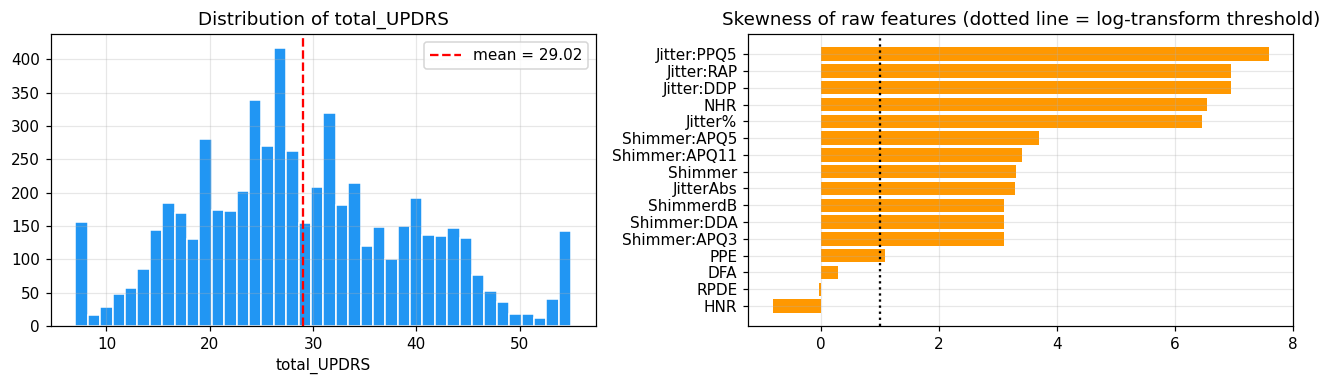

corr(Jitter:DDP, Jitter:RAP) = 1.000000
corr(Shimmer:DDA, Shimmer:APQ3) = 1.000000

Pearson correlation of every raw feature with the target:
HNR             -0.162
DFA             -0.113
NHR              0.061
Jitter:PPQ5      0.063
Jitter:RAP       0.064
Jitter:DDP       0.064
JitterAbs        0.067
Jitter%          0.074
Shimmer:APQ3     0.079
Shimmer:DDA      0.079
Shimmer:APQ5     0.083
Shimmer          0.092
ShimmerdB        0.099
Shimmer:APQ11    0.121
PPE              0.156
RPDE             0.157


In [ ]:
# =============================================================================
# 4.1 TARGET, SKEWNESS AND REDUNDANCY OF THE RAW FEATURES
# =============================================================================
print(y_all.describe().round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(y_all, bins=40, color="#2196F3", edgecolor="white")
ax[0].axvline(y_all.mean(), color="red", ls="--", label=f"mean = {y_all.mean():.2f}")
ax[0].set_title("Distribution of total_UPDRS"); ax[0].set_xlabel("total_UPDRS"); ax[0].legend()

skew_raw = X_all.skew().sort_values()
ax[1].barh(skew_raw.index, skew_raw.values, color="#FF9800")
ax[1].axvline(SKEW_THRESHOLD, color="k", ls=":")
ax[1].set_title("Skewness of raw features (dotted line = log-transform threshold)")
plt.tight_layout(); plt.show()

# Some voice features are exact multiples of others BY DEFINITION (Jitter:DDP = 3*Jitter:RAP and
# Shimmer:DDA = 3*Shimmer:APQ3).  Duplicated information => X^T X is (almost) singular.
for a, b in [("Jitter:DDP", "Jitter:RAP"), ("Shimmer:DDA", "Shimmer:APQ3")]:
    print(f"corr({a}, {b}) = {np.corrcoef(df[a], df[b])[0, 1]:.6f}")

corr_raw = X_all.corrwith(y_all).sort_values()
print("\nPearson correlation of every raw feature with the target:")
print(corr_raw.round(3).to_string())

# 5. FEATURE ENGINEERING

The transformations are chosen because they change the **geometry of the optimization problem** as well as the statistics of the data:

| Step | What it does | Why it helps |
|---|---|---|
| 1. Domain feature | `log(Shimmer) - log(Jitter%)` = amplitude instability relative to frequency instability | a ratio a linear model cannot build by itself |
| 2. Log transform | applied to right-skewed positive features (skewness > threshold) | removes heavy tails, makes relations closer to linear |
| 3. Winsorizing | clips each feature to its 1st–99th percentile | limits the leverage of extreme recordings |
| 4. Collinearity pruning | of two features with $|r|>0.95$ keep the one more correlated with the target | removes (near-)duplicate columns, so $\lambda_{\min}(H)$ is no longer ≈ 0 and **Newton/BFGS can invert/approximate $H$ reliably** |
| 5. Standardization | zero mean, unit variance | puts all weights on the same scale, which **drastically reduces the condition number** and makes gradient methods usable |

**No leakage:** every parameter (skewness decision, percentiles, correlations, means, standard deviations) is learned on the *training* data only and re-used on validation/test data. The class below follows the `fit` / `transform` pattern and is re-fitted inside every cross-validation fold.

In [ ]:
# =============================================================================
# 5.1 FeatureEngineer — fit on training data, transform any data
# =============================================================================
class FeatureEngineer:
    """Log transform -> winsorize -> collinearity pruning -> standardization.

    fit(X, y)   : learns all parameters from the TRAINING data only.
    transform(X): applies the learned parameters to any data (train / validation / test).
    """

    def __init__(self, skew_threshold=SKEW_THRESHOLD, winsor_pct=WINSOR_PCT, corr_threshold=CORR_THRESHOLD):
        self.skew_threshold = skew_threshold
        self.winsor_pct = winsor_pct
        self.corr_threshold = corr_threshold

    # -- step 1: domain feature ------------------------------------------------
    @staticmethod
    def _add_domain_features(X):
        Z = X.copy()
        if {"Shimmer", "Jitter%"} <= set(Z.columns):
            # amplitude perturbation relative to frequency perturbation (difference of logs = log ratio)
            Z["log_Shimmer_over_Jitter"] = (np.log(np.clip(Z["Shimmer"], 1e-12, None))
                                            - np.log(np.clip(Z["Jitter%"], 1e-12, None)))
        return Z

    # -- step 2: log transform of the chosen columns -----------------------------
    def _log_step(self, Z):
        Z = Z.copy()
        for c in self.log_cols_:
            Z[c] = np.log(np.clip(Z[c], 1e-12, None))   # clip protects against log(0) on new data
        return Z

    def fit(self, X, y):
        y_arr = np.asarray(y, dtype=float)
        Z = self._add_domain_features(X)

        # step 2: decide (on train) which columns are skewed AND strictly positive
        skew_before = Z.skew()
        self.log_cols_ = [c for c in Z.columns if skew_before[c] > self.skew_threshold and Z[c].min() > 0]
        Z = self._log_step(Z)
        skew_after = Z.skew()

        # step 3: winsorizing bounds from train percentiles
        self.lo_ = Z.quantile(self.winsor_pct[0] / 100.0)
        self.hi_ = Z.quantile(self.winsor_pct[1] / 100.0)
        Z = Z.clip(lower=self.lo_, upper=self.hi_, axis=1)

        # step 4: greedy collinearity pruning. Visit features from most to least correlated with the
        # target; keep a feature unless it is too correlated with one that was already kept.
        corr_y = Z.apply(lambda s: np.corrcoef(s.values, y_arr)[0, 1]).abs().sort_values(ascending=False)
        corr_X = Z.corr().abs()
        kept, dropped = [], {}
        for c in corr_y.index:
            clash = [k for k in kept if corr_X.loc[c, k] > self.corr_threshold]
            if clash:
                dropped[c] = f"{clash[0]} (|r|={corr_X.loc[c, clash[0]]:.3f})"
            else:
                kept.append(c)
        self.kept_ = kept
        self.dropped_ = dropped
        Z = Z[kept]

        # step 5: standardization parameters
        self.mean_ = Z.mean()
        self.std_ = Z.std(ddof=0).replace(0, 1.0)

        # human-readable summary of what happened to each feature
        self.summary_ = pd.DataFrame({
            "skew_raw": skew_before,
            "log_transformed": [c in self.log_cols_ for c in skew_before.index],
            "skew_after_log": skew_after,
            "kept": [c in kept for c in skew_before.index],
            "dropped_because_correlated_with": [dropped.get(c, "") for c in skew_before.index],
        })
        return self

    def transform(self, X):
        Z = self._add_domain_features(X)
        Z = self._log_step(Z)
        Z = Z.clip(lower=self.lo_, upper=self.hi_, axis=1)[self.kept_]
        return (Z - self.mean_) / self.std_

In [ ]:
# =============================================================================
# 5.2 PATIENT-WISE TRAIN / TEST SPLIT, THEN FIT THE FEATURE ENGINEERING ON TRAIN
# =============================================================================
# All recordings of one patient stay on the same side of the split, so the test set contains
# patients the model has never seen (same protocol as the previous notebook).
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(gss.split(X_all, y_all, groups=groups))

X_train_raw = X_all.iloc[train_idx].reset_index(drop=True)
X_test_raw = X_all.iloc[test_idx].reset_index(drop=True)
y_train = y_all.iloc[train_idx].reset_index(drop=True)
y_test = y_all.iloc[test_idx].reset_index(drop=True)
groups_train = groups.iloc[train_idx].reset_index(drop=True)

print(f"Train: {len(X_train_raw)} recordings from {groups_train.nunique()} patients")
print(f"Test : {len(X_test_raw)} recordings from {groups.iloc[test_idx].nunique()} patients")
print("Patients in both sets:", len(set(groups_train) & set(groups.iloc[test_idx])))

fe = FeatureEngineer().fit(X_train_raw, y_train)
F_train = fe.transform(X_train_raw)
F_test = fe.transform(X_test_raw)

print("\nLog-transformed :", fe.log_cols_)
print("Kept            :", fe.kept_)
print("Dropped         :", fe.dropped_)
print(f"\nFeatures: {X_train_raw.shape[1]} raw  ->  {F_train.shape[1]} engineered")
display(fe.summary_.round(3))

Train: 4640 recordings from 33 patients
Test : 1235 recordings from 9 patients
Patients in both sets: 0

Log-transformed : ['Jitter%', 'JitterAbs', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'ShimmerdB', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'PPE']
Kept            : ['PPE', 'Jitter%', 'Shimmer:APQ11', 'HNR', 'NHR', 'JitterAbs', 'Shimmer:DDA', 'RPDE', 'DFA', 'log_Shimmer_over_Jitter']
Dropped         : {'Jitter:PPQ5': 'Jitter% (|r|=0.967)', 'Jitter:DDP': 'Jitter% (|r|=0.969)', 'Jitter:RAP': 'Jitter% (|r|=0.969)', 'ShimmerdB': 'Shimmer:APQ11 (|r|=0.955)', 'Shimmer': 'Shimmer:APQ11 (|r|=0.964)', 'Shimmer:APQ5': 'Shimmer:APQ11 (|r|=0.963)', 'Shimmer:APQ3': 'Shimmer:DDA (|r|=1.000)'}

Features: 16 raw  ->  10 engineered


,skew_raw,log_transformed,skew_after_log,kept,dropped_because_correlated_with
Jitter%,5.264,True,0.936,True,
JitterAbs,3.476,True,0.151,True,
Jitter:RAP,5.551,True,0.845,False,Jitter% (|r|=0.969)
Jitter:PPQ5,6.492,True,1.186,False,Jitter% (|r|=0.967)
Jitter:DDP,5.551,True,0.845,False,Jitter% (|r|=0.969)
Shimmer,3.398,True,0.592,False,Shimmer:APQ11 (|r|=0.964)
ShimmerdB,3.181,True,0.563,False,Shimmer:APQ11 (|r|=0.955)
Shimmer:APQ3,3.206,True,0.390,False,Shimmer:DDA (|r|=1.000)
Shimmer:APQ5,3.822,True,0.555,False,Shimmer:APQ11 (|r|=0.963)
Shimmer:APQ11,3.434,True,0.427,True,


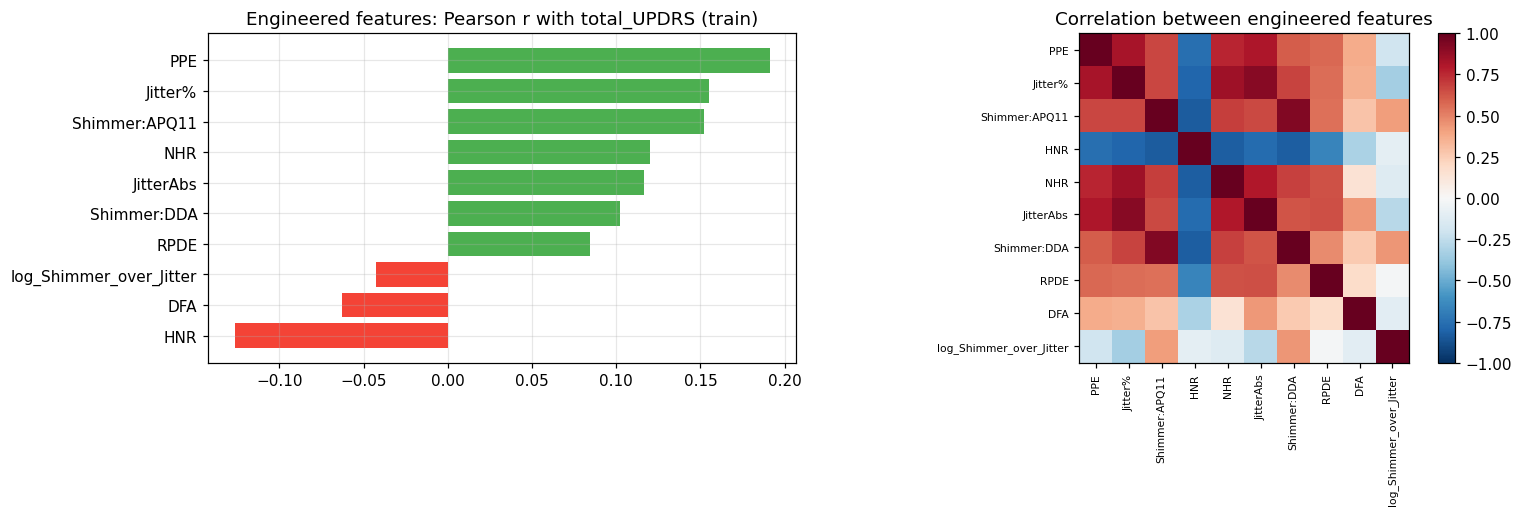

In [ ]:
# =============================================================================
# 5.3 ENGINEERED FEATURES: correlation with the target and between features
# =============================================================================
corr_eng = F_train.corrwith(y_train).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].barh(corr_eng.index, corr_eng.values, color=np.where(corr_eng.values >= 0, "#4CAF50", "#F44336"))
ax[0].set_title("Engineered features: Pearson r with total_UPDRS (train)")

C = F_train.corr().values
im = ax[1].imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(F_train.columns))); ax[1].set_xticklabels(F_train.columns, rotation=90, fontsize=7)
ax[1].set_yticks(range(len(F_train.columns))); ax[1].set_yticklabels(F_train.columns, fontsize=7)
ax[1].set_title("Correlation between engineered features"); ax[1].grid(False)
fig.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()

# 6. THE OPTIMIZATION PROBLEM

The next cells turn the data into the objective $f(w)$ of Section 2.

* `build_design` creates the design matrix $A$ (intercept column + engineered features, optionally expanded with `PolynomialFeatures`; polynomial terms are re-standardized so that they are on the same scale).
* `LeastSquares` provides $f$, $\nabla f$ and $\nabla^2 f$ — exactly the three oracles that the optimizers of the lesson need.

In [ ]:
# =============================================================================
# 6.1 DESIGN MATRIX (optionally polynomial) AND THE OBJECTIVE FUNCTION
# =============================================================================
def build_design(F_tr, y_tr, F_te, degree=1, top_k=None):
    """Return design matrices (with a leading column of ones) for train and test.

    degree = 1 -> linear regression; degree > 1 -> polynomial regression (PolynomialFeatures).
    top_k      -> use only the k engineered features most correlated with the target (selected on
                  the training data), which keeps the number of polynomial terms manageable.
    """
    y_arr = np.asarray(y_tr, dtype=float)
    cols = list(F_tr.columns)
    if top_k is not None and top_k < len(cols):
        r = F_tr.apply(lambda s: abs(np.corrcoef(s.values, y_arr)[0, 1]))
        cols = r.sort_values(ascending=False).index[:top_k].tolist()

    P_tr, P_te = F_tr[cols].values, F_te[cols].values
    names = cols
    if degree > 1:
        pf = PolynomialFeatures(degree=degree, include_bias=False)   # x1, x2, x1^2, x1*x2, x2^2, ...
        P_tr, P_te = pf.fit_transform(P_tr), pf.transform(P_te)
        names = list(pf.get_feature_names_out(cols))
        sc = StandardScaler().fit(P_tr)                              # re-scale the polynomial terms
        P_tr, P_te = sc.transform(P_tr), sc.transform(P_te)

    A_tr = np.hstack([np.ones((len(P_tr), 1)), P_tr])                # intercept = weight of the ones column
    A_te = np.hstack([np.ones((len(P_te), 1)), P_te])
    return A_tr, A_te, ["intercept"] + names


class LeastSquares:
    """f(w) = 1/(2n) * ||A w - y||^2  together with its gradient and Hessian."""

    def __init__(self, A, y):
        self.A = np.asarray(A, dtype=float)
        self.y = np.asarray(y, dtype=float)
        self.n, self.d = self.A.shape
        self.H = self.A.T @ self.A / self.n           # Hessian: constant, because f is quadratic
        self.b = self.A.T @ self.y / self.n           # so that grad f(w) = H w - b

    def f(self, w):                                   # objective value (residual form: most accurate)
        r = self.A @ w - self.y
        return 0.5 * float(r @ r) / self.n

    def grad(self, w):                                # (1/n) A^T (A w - y)  ==  H w - b   (cheaper: O(d^2))
        return self.H @ w - self.b

    def hess(self, w):                                # Newton-type methods need this
        return self.H

    def solve_closed_form(self):
        """Reference solution (normal equations / least squares) -- used ONLY to judge the optimizers."""
        w = np.linalg.lstsq(self.A, self.y, rcond=None)[0]
        return w, self.f(w)


def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

,n_columns,lambda_min,lambda_max,kappa
Design matrix,,,,
Raw features (no scaling),17,6.487112e-12,493.390059,7.605696e+13
Raw features (standardized),17,1.953215e-08,11.525318,5.900689e+08
Engineered features,11,7.500502e-03,6.178027,8.236818e+02


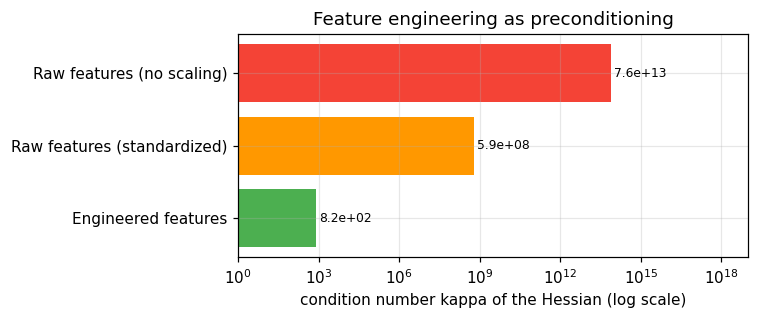

In [ ]:
# =============================================================================
# 6.2 CONDITION NUMBER OF THE HESSIAN: raw features vs engineered features
# =============================================================================
# kappa = lambda_max(H) / lambda_min(H).  The larger kappa, the harder the problem for first-order methods.
def hessian_spectrum(A):
    """Return (lambda_min, lambda_max, kappa) of H = A^T A / n.
    If lambda_min is not distinguishable from 0 in floating point (exactly duplicated columns),
    H is numerically singular and kappa is reported as infinity."""
    H = A.T @ A / len(A)
    ev = np.linalg.eigvalsh(H)                        # eigenvalues in ascending order (symmetric matrix)
    tol = np.finfo(float).eps * H.shape[0] * ev[-1]   # rounding-error level of the eigenvalue computation
    kappa = np.inf if ev[0] <= tol else ev[-1] / ev[0]
    return ev[0], ev[-1], kappa


def fmt_kappa(k):
    return "infinite (numerically singular)" if not np.isfinite(k) else f"{k:.2e}"


ones = np.ones((len(X_train_raw), 1))
A_raw_unscaled = np.hstack([ones, X_train_raw.values])                                   # raw numbers
A_raw_std = np.hstack([ones, StandardScaler().fit_transform(X_train_raw.values)])        # only standardized
A_eng, _, _ = build_design(F_train, y_train, F_test, degree=1)                           # engineered (+ standardized)

cond_rows = []
for label, A in [("Raw features (no scaling)", A_raw_unscaled),
                 ("Raw features (standardized)", A_raw_std),
                 ("Engineered features", A_eng)]:
    lo, hi, kappa = hessian_spectrum(A)
    cond_rows.append({"Design matrix": label, "n_columns": A.shape[1], "lambda_min": lo, "lambda_max": hi, "kappa": kappa})
cond_df = pd.DataFrame(cond_rows).set_index("Design matrix")
display(cond_df)

fig, ax = plt.subplots(figsize=(7, 3))
KAPPA_CAP = 1e16                                   # bars of singular matrices are drawn at this value
ax.barh(cond_df.index, np.minimum(cond_df["kappa"], KAPPA_CAP), color=["#F44336", "#FF9800", "#4CAF50"])
for i, k in enumerate(cond_df["kappa"]):
    ax.text(min(k, KAPPA_CAP) * 1.3, i, "singular" if not np.isfinite(k) else f"{k:.1e}", va="center", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("condition number kappa of the Hessian (log scale)")
ax.set_xlim(1, KAPPA_CAP * 1e3); ax.invert_yaxis(); ax.set_title("Feature engineering as preconditioning")
plt.tight_layout(); plt.show()

# 7. OPTIMIZERS AND LEARNING-RATE STRATEGIES

All optimizers minimize the **same** function `LeastSquares.f` starting from the **same** point $w_0=0$.

| Name in tables | Family | How the step / direction is obtained | Implementation |
|---|---|---|---|
| GD (fixed step 1/L) | first-order | constant step $1/L$, $L=\lambda_{\max}(H)$ (baseline *without* line search) | short loop |
| GD (exact line search) | first-order | $\alpha_k=\frac{g^\top g}{g^\top H g}$ (exact minimizer on the line) | short loop |
| GD (Wolfe line search) | first-order | step satisfying the Wolfe conditions | loop + `scipy.optimize.line_search` |
| Nesterov + adaptive restart | momentum | accelerated gradient; momentum is reset when it points uphill | short loop |
| Adam (plateau decay) | adaptive / momentum | per-coordinate step from running gradient moments; learning rate halved when progress stalls | short loop |
| Conjugate Gradient (CG) | conjugate gradient | Polak–Ribière directions + line search | `minimize(method="CG")` |
| BFGS | quasi-Newton | $H^{-1}$ approximation + Wolfe line search | `minimize(method="BFGS")` |
| L-BFGS-B | limited-memory quasi-Newton | last $m$ gradient pairs | `minimize(method="L-BFGS-B")` |
| Newton-CG | Newton | solves $H p=-g$ inexactly with CG, using the Hessian | `minimize(method="Newton-CG")` |
| Newton (trust-region) | Newton | exact Hessian factorization inside a trust region | `minimize(method="trust-exact")` |
| Nelder-Mead | derivative-free | simplex, no gradients (only for small $d$) | `minimize(method="Nelder-Mead")` |

**How accuracy is measured.** Every iterate $w_k$ is stored. After the run we compute the exact sub-optimality $f(w_k)-f(w^\star)=\tfrac12(w_k-w^\star)^\top H(w_k-w^\star)$. This is done *outside* the timer, so the reported time contains only the optimizer's own work. "Converged" means sub-optimality below `CONV_TOL`.

In [ ]:
# =============================================================================
# 7.1 CUSTOM LOOPS FOR THE METHODS THAT SCIPY DOES NOT PROVIDE
# =============================================================================
N_GD_FIXED = "GD (fixed step 1/L)"
N_GD_EXACT = "GD (exact line search)"
N_GD_WOLFE = "GD (Wolfe line search)"
N_NESTEROV = "Nesterov + adaptive restart"
N_ADAM = "Adam (plateau decay)"
N_CG = "Conjugate Gradient (CG)"
N_BFGS = "BFGS (quasi-Newton)"
N_LBFGS = "L-BFGS-B (limited-memory QN)"
N_NCG = "Newton-CG"
N_TRUST = "Newton (trust-region, exact Hessian)"
N_NM = "Nelder-Mead (derivative-free)"


def pack(name, family, iterates, elapsed, nfev=0, ngev=0, nhev=0, steps=None):
    """Store one optimizer run in a dictionary."""
    return {"name": name, "family": family, "iterates": np.asarray(iterates), "time": elapsed,
            "nit": len(iterates) - 1, "nfev": nfev, "ngev": ngev, "nhev": nhev,
            "steps": list(steps) if steps is not None else []}


def gd_fixed(obj, w0, alpha, max_iter, gtol=1e-8):
    """Gradient descent with a constant step:  w <- w - alpha * grad f(w)."""
    w, its, steps, ngev = w0.copy(), [w0.copy()], [], 0
    t0 = time.perf_counter()
    for _ in range(max_iter):
        g = obj.grad(w); ngev += 1
        if np.linalg.norm(g, np.inf) < gtol:             # stop when the gradient is (almost) zero
            break
        w = w - alpha * g
        its.append(w.copy()); steps.append(alpha)
    return pack(N_GD_FIXED, "First-order", its, time.perf_counter() - t0, 0, ngev, 0, steps)


def gd_exact_line_search(obj, w0, max_iter, gtol=1e-8):
    """Steepest descent where the step is the EXACT minimizer of f(w - alpha*g) over alpha.
    For a quadratic this has the closed form  alpha = (g.g) / (g.H.g)."""
    w, its, steps, ngev = w0.copy(), [w0.copy()], [], 0
    t0 = time.perf_counter()
    for _ in range(max_iter):
        g = obj.grad(w); ngev += 1
        if np.linalg.norm(g, np.inf) < gtol:
            break
        curvature = g @ (obj.H @ g)
        if curvature <= 0:
            break
        alpha = (g @ g) / curvature
        w = w - alpha * g
        its.append(w.copy()); steps.append(alpha)
    return pack(N_GD_EXACT, "First-order", its, time.perf_counter() - t0, 0, ngev, 0, steps)


def gd_wolfe_line_search(obj, w0, max_iter, gtol=1e-8):
    """Steepest descent where the step satisfies the (strong) Wolfe conditions.
    scipy.optimize.line_search does the work; the previous function values give it a good first guess."""
    w, its, steps = w0.copy(), [w0.copy()], []
    f_old, f_old_old = obj.f(w), None
    nfev, ngev = 1, 0
    t0 = time.perf_counter()
    for _ in range(max_iter):
        g = obj.grad(w); ngev += 1
        if np.linalg.norm(g, np.inf) < gtol:
            break
        p = -g                                            # steepest-descent direction
        with warnings.catch_warnings():                   # near the optimum f changes at rounding-error level;
            warnings.simplefilter("ignore")               # SciPy then warns and returns alpha=None, handled below
            out = line_search(obj.f, obj.grad, w, p, gfk=g, old_fval=f_old, old_old_fval=f_old_old,
                              c1=1e-4, c2=0.9)           # returns (alpha, n_f, n_g, f_new, f_old, slope)
        alpha = out[0]
        if alpha is None:                                 # rare failure -> fall back to the exact step
            alpha = (g @ g) / (g @ (obj.H @ g))
        else:
            nfev += out[1]; ngev += out[2]
        w = w + alpha * p
        f_old_old, f_old = f_old, obj.f(w); nfev += 1
        its.append(w.copy()); steps.append(alpha)
    return pack(N_GD_WOLFE, "First-order", its, time.perf_counter() - t0, nfev, ngev, 0, steps)


def nesterov_restart(obj, w0, L, max_iter, gtol=1e-8):
    """Nesterov accelerated gradient with gradient-based adaptive restart (O'Donoghue & Candes).
    Step 1/L; the momentum weight grows like (theta-1)/theta_new and is RESET to zero whenever the
    gradient at the look-ahead point and the last move disagree (momentum would go uphill)."""
    x_prev, y = w0.copy(), w0.copy()
    theta, its, steps, ngev = 1.0, [w0.copy()], [], 0
    t0 = time.perf_counter()
    for _ in range(max_iter):
        g = obj.grad(y); ngev += 1
        if np.linalg.norm(g, np.inf) < gtol:
            break
        x_new = y - g / L                                 # gradient step from the look-ahead point
        if g @ (x_new - x_prev) > 0:                      # momentum points uphill -> restart
            theta = 1.0
            y = x_new.copy()
        else:
            theta_new = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * theta ** 2))
            beta = (theta - 1.0) / theta_new              # momentum coefficient
            y = x_new + beta * (x_new - x_prev)
            theta = theta_new
        x_prev = x_new
        its.append(x_new.copy()); steps.append(1.0 / L)
    return pack(N_NESTEROV, "Momentum", its, time.perf_counter() - t0, 0, ngev, 0, steps)


def adam(obj, w0, lr0=0.05, max_iter=10000, gtol=1e-8, beta1=0.9, beta2=0.999, eps=1e-8,
         patience=50, decay=0.5):
    """Adam (full-batch).  The learning rate is NOT fixed: whenever the gradient norm has not improved
    for `patience` iterations it is multiplied by `decay` ('reduce on plateau')."""
    w = w0.copy()
    m, v = np.zeros_like(w), np.zeros_like(w)
    lr, best, stall = lr0, np.inf, 0
    its, steps, ngev = [w0.copy()], [], 0
    t0 = time.perf_counter()
    for k in range(1, max_iter + 1):
        g = obj.grad(w); ngev += 1
        gn = np.linalg.norm(g, np.inf)
        if gn < gtol or lr < 1e-12:
            break
        if gn < 0.99 * best:                              # progress -> remember it
            best, stall = gn, 0
        else:                                             # no progress -> maybe shrink the learning rate
            stall += 1
            if stall >= patience:
                lr *= decay; stall = 0
        m = beta1 * m + (1 - beta1) * g                   # first moment  (momentum)
        v = beta2 * v + (1 - beta2) * g * g               # second moment (per-coordinate scale)
        m_hat, v_hat = m / (1 - beta1 ** k), v / (1 - beta2 ** k)   # bias correction
        w = w - lr * m_hat / (np.sqrt(v_hat) + eps)
        its.append(w.copy()); steps.append(lr)
    return pack(N_ADAM, "Momentum", its, time.perf_counter() - t0, 0, ngev, 0, steps)

In [ ]:
# =============================================================================
# 7.2 SCIPY OPTIMIZERS (used directly) AND THE FUNCTION THAT RUNS THEM ALL
# =============================================================================
def run_scipy(obj, w0, method, name, family, use_jac=True, use_hess=False, options=None):
    """Call scipy.optimize.minimize and record every iterate through the callback."""
    its = [w0.copy()]
    callback = lambda xk: its.append(np.array(xk, copy=True))        # called once per iteration
    t0 = time.perf_counter()
    res = minimize(obj.f, w0, jac=obj.grad if use_jac else None,
                   hess=obj.hess if use_hess else None, method=method,
                   callback=callback, options=options or {})
    elapsed = time.perf_counter() - t0
    its.append(np.array(res.x, copy=True))                           # make sure the final point is stored
    return pack(name, family, its, elapsed,
                nfev=int(res.get("nfev", 0)), ngev=int(res.get("njev", 0)), nhev=int(res.get("nhev", 0)))


def run_all_optimizers(obj, w0, only=None, include_nm=True, max_iter=MAX_ITER_FIRST_ORDER, repeats=TIMING_REPEATS):
    """Run every optimizer on `obj` from `w0` and return {name: result}.
    The runs are deterministic, so repeating them only improves the timing: the fastest time is kept."""
    L = np.linalg.eigvalsh(obj.H)[-1]                 # smoothness constant = largest eigenvalue of H
    runners = {
        N_GD_FIXED: lambda: gd_fixed(obj, w0, 1.0 / L, max_iter),
        N_GD_EXACT: lambda: gd_exact_line_search(obj, w0, max_iter),
        N_GD_WOLFE: lambda: gd_wolfe_line_search(obj, w0, max_iter),
        N_NESTEROV: lambda: nesterov_restart(obj, w0, L, max_iter),
        N_ADAM: lambda: adam(obj, w0, max_iter=max_iter),
        N_CG: lambda: run_scipy(obj, w0, "CG", N_CG, "Conjugate gradient",
                                options=dict(gtol=1e-8, maxiter=max_iter)),
        N_BFGS: lambda: run_scipy(obj, w0, "BFGS", N_BFGS, "Quasi-Newton",
                                  options=dict(gtol=1e-8, maxiter=max_iter)),
        N_LBFGS: lambda: run_scipy(obj, w0, "L-BFGS-B", N_LBFGS, "Quasi-Newton",
                                   options=dict(maxiter=max_iter, maxfun=10**7, ftol=1e-15, gtol=1e-10)),
        N_NCG: lambda: run_scipy(obj, w0, "Newton-CG", N_NCG, "Newton", use_hess=True,
                                 options=dict(xtol=1e-12, maxiter=1000)),
        N_TRUST: lambda: run_scipy(obj, w0, "trust-exact", N_TRUST, "Newton", use_hess=True,
                                   options=dict(gtol=1e-10, maxiter=500)),
    }
    if include_nm:                                    # derivative-free: only sensible when d is small
        runners[N_NM] = lambda: run_scipy(obj, w0, "Nelder-Mead", N_NM, "Derivative-free", use_jac=False,
                                          options=dict(maxiter=50000, maxfev=100000, xatol=1e-10,
                                                       fatol=1e-12, adaptive=True))
    if only is not None:
        runners = {k: v for k, v in runners.items() if k in only}
    results = {}
    for name, run in runners.items():
        runs = [run() for _ in range(repeats)]
        best = runs[-1]
        best["time"] = min(r["time"] for r in runs)       # least-disturbed measurement
        results[name] = best
    return results


# -----------------------------------------------------------------------------
# 7.3 EVALUATION HELPERS
# -----------------------------------------------------------------------------
def suboptimality(iterates, obj, w_star):
    """Exact f(w_k) - f(w*) for every stored iterate:  0.5 * (w-w*)^T H (w-w*)."""
    D = np.asarray(iterates) - w_star
    return 0.5 * np.einsum("ij,ij->i", D @ obj.H, D)


def summarize(results, obj, w_star, A_test=None, y_test_vals=None):
    """One row per optimizer: cost (iterations, evaluations, time) and accuracy."""
    rows, gaps = [], {}
    for name, r in results.items():
        gap = suboptimality(r["iterates"], obj, w_star)
        gaps[name] = gap
        w = r["iterates"][-1]
        hit = np.where(gap < CONV_TOL)[0]
        row = {"Optimizer": name, "Family": r["family"], "Iterations": r["nit"],
               "f evals": r["nfev"], "grad evals": r["ngev"], "Hess evals": r["nhev"],
               "Time (s)": r["time"], "Final f-f*": gap[-1],
               "Rel. error ||w-w*||/||w*||": np.linalg.norm(w - w_star) / max(np.linalg.norm(w_star), 1e-300),
               "Iters to tol": int(hit[0]) if len(hit) else np.nan,
               "Converged": bool(len(hit))}
        if A_test is not None:
            row["Test RMSE"] = rmse(y_test_vals, A_test @ w)
        rows.append(row)
    return pd.DataFrame(rows).set_index("Optimizer"), gaps


def show_table(tbl):
    """Pretty-print a results table (scientific notation for tiny numbers)."""
    out = tbl.copy()
    for c in ["Final f-f*", "Rel. error ||w-w*||/||w*||"]:
        if c in out:
            out[c] = out[c].map(lambda v: f"{v:.2e}")
    if "Time (s)" in out:
        out["Time (s)"] = out["Time (s)"].map(lambda v: f"{v:.4f}")
    if "Test RMSE" in out:
        out["Test RMSE"] = out["Test RMSE"].map(lambda v: f"{v:.4f}")
    display(out)


def plot_convergence(results, gaps, title):
    """Left: sub-optimality vs iteration (log-log). Right: wall-clock time. Bottom: step sizes of GD variants."""
    styles = ["-", "--", "-.", ":"]
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    for i, (name, g) in enumerate(gaps.items()):
        ax[0].loglog(np.arange(len(g)) + 1, np.maximum(g, 1e-20), styles[i % 4], lw=1.8, label=name)
    ax[0].axhline(CONV_TOL, color="k", lw=1, ls=":")
    ax[0].set_xlabel("iteration (log scale)"); ax[0].set_ylabel("f(w_k) - f(w*)  (log scale)")
    ax[0].set_title(title); ax[0].set_ylim(1e-14, None); ax[0].legend(fontsize=7)

    names = list(results.keys())
    times = [results[n]["time"] for n in names]
    ax[1].barh(names, times, color="#2196F3")
    ax[1].set_xscale("log"); ax[1].set_xlabel("time in seconds (log scale)")
    ax[1].set_title("Optimizer run time"); ax[1].invert_yaxis()
    plt.tight_layout(); plt.show()

    # Learning rate actually used by the gradient-type methods
    with_steps = {n: r["steps"] for n, r in results.items() if len(r["steps"]) > 1}
    if with_steps:
        fig, ax = plt.subplots(figsize=(8, 3.6))
        for i, (n, s) in enumerate(with_steps.items()):
            ax.semilogy(np.arange(1, len(s) + 1), s, styles[i % 4], lw=1.5, label=n)
        ax.set_xscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("step size / learning rate")
        ax.set_title("Learning rate chosen by each method"); ax.legend(fontsize=7)
        plt.tight_layout(); plt.show()

# 8. EXPERIMENT A — OPTIMIZER COMPARISON ON LINEAR REGRESSION

Model: $\hat y = w_0 + \sum_j w_j x_j$ on **all engineered features**. All optimizers start at $w_0=0$ and are compared with the closed-form solution.

*How to read the table:* `Iterations` is the number the solver actually used; `Iters to tol` is the first iteration where $f-f^\star<10^{-6}$ (comparable across solvers that use different stopping rules); `Converged = False` means the iteration cap was reached first.

In [ ]:
# =============================================================================
# 8.1 RUN ALL OPTIMIZERS ON THE LINEAR MODEL
# =============================================================================
A_lin_tr, A_lin_te, names_lin = build_design(F_train, y_train, F_test, degree=1, top_k=None)
obj_lin = LeastSquares(A_lin_tr, y_train.values)
w_star_lin, f_star_lin = obj_lin.solve_closed_form()
w0_lin = np.zeros(obj_lin.d)

print(f"Linear model: n = {obj_lin.n} recordings, d = {obj_lin.d} weights (incl. intercept)")
print(f"f(w0) = {obj_lin.f(w0_lin):.4f}   f(w*) = {f_star_lin:.4f}   (f* = half of the best achievable training MSE)")
lo_lin, hi_lin, kappa_lin = hessian_spectrum(obj_lin.A)
print(f"lambda_min = {lo_lin:.3e}, lambda_max = {hi_lin:.3e}, kappa = {fmt_kappa(kappa_lin)}")

# Warm-up: run everything once on a tiny dummy problem so that one-off start-up costs (lazy imports,
# first-call overhead) do not distort the timings of the first real run.
_rng = np.random.default_rng(0)
_ = run_all_optimizers(LeastSquares(_rng.normal(size=(50, 3)), _rng.normal(size=50)), np.zeros(3), max_iter=50, repeats=1)

res_lin = run_all_optimizers(obj_lin, w0_lin, include_nm=True)
tbl_lin, gaps_lin = summarize(res_lin, obj_lin, w_star_lin, A_lin_te, y_test.values)
show_table(tbl_lin)

Linear model: n = 4640 recordings, d = 11 weights (incl. intercept)
f(w0) = 497.7972   f(w*) = 55.2594   (f* = half of the best achievable training MSE)
lambda_min = 7.501e-03, lambda_max = 6.178e+00, kappa = 8.24e+02


,Family,Iterations,f evals,grad evals,Hess evals,Time (s),Final f-f*,Rel. error ||w-w*||/||w*||,Iters to tol,Converged,Test RMSE
Optimizer,,,,,,,,,,,
GD (fixed step 1/L),First-order,10000,0,10000,0,0.3123,2.79e-12,8.83e-07,4737,True,9.6375
GD (exact line search),First-order,3186,0,3187,0,0.1278,1.77e-14,7.03e-08,1251,True,9.6375
GD (Wolfe line search),First-order,4558,9040,8907,0,2.0244,2.50e-15,2.64e-08,1994,True,9.6375
Nesterov + adaptive restart,Momentum,453,0,454,0,0.0406,1.23e-15,6.32e-09,206,True,9.6375
Adam (plateau decay),Momentum,3059,0,3060,0,0.1727,4.89e-17,3.20e-10,2105,True,9.6375
Conjugate Gradient (CG),Conjugate gradient,152,311,300,0,0.0695,2.95e-14,7.57e-08,81,True,9.6375
BFGS (quasi-Newton),Quasi-Newton,38,41,41,0,0.0127,9.78e-17,1.53e-09,31,True,9.6375
L-BFGS-B (limited-memory QN),Quasi-Newton,52,60,60,0,0.0118,1.01e-13,7.69e-08,34,True,9.6375
Newton-CG,Newton,11,10,10,10,0.0039,1.80e-14,1.99e-08,7,True,9.6375


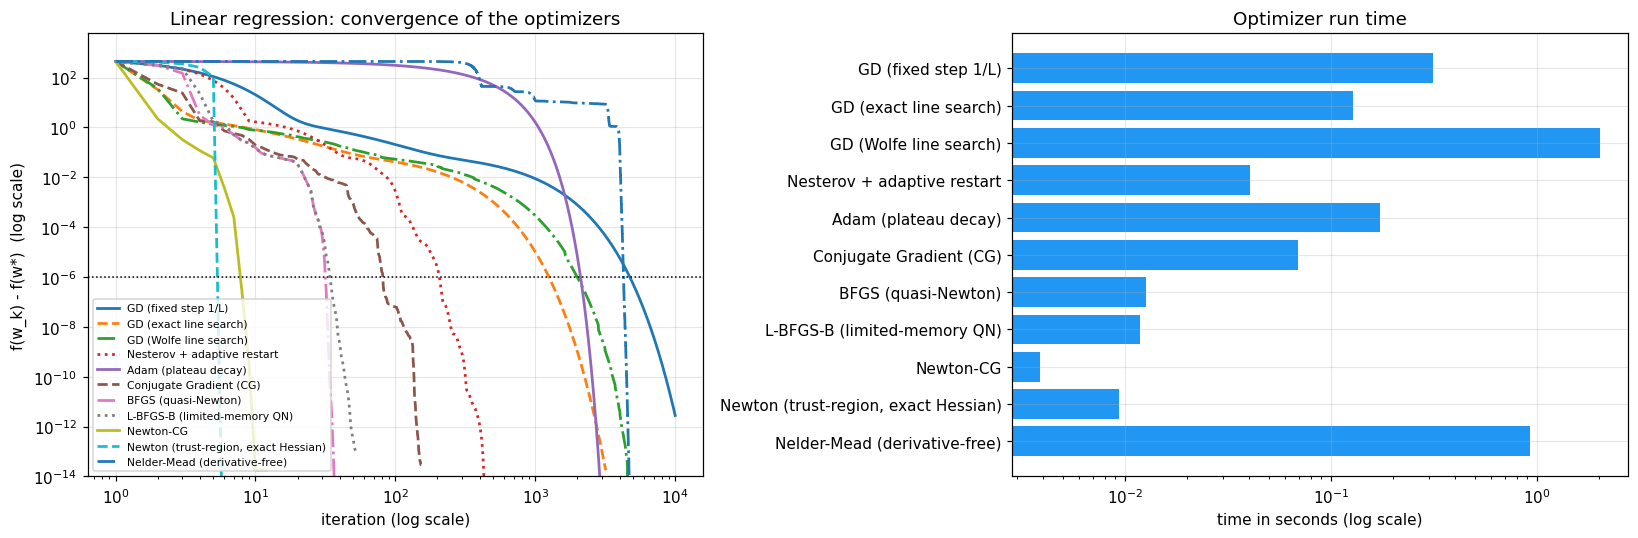

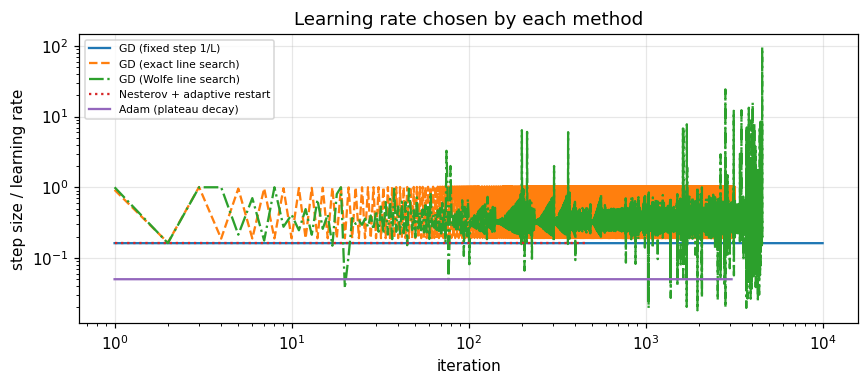

In [ ]:
# =============================================================================
# 8.2 CONVERGENCE CURVES AND LEARNING RATES (linear model)
# =============================================================================
plot_convergence(res_lin, gaps_lin, "Linear regression: convergence of the optimizers")

**How to interpret Experiment A.** The curves show how fast each method reduces $f(w_k)-f(w^\star)$. Methods that use second-order information (Newton, BFGS, L-BFGS) or conjugate directions are expected to need far fewer iterations than gradient descent, whose speed depends on the condition number. The step-size plot shows what the learning-rate strategies actually did: the fixed step never changes, the line searches adapt the step to the local curvature at every iteration, and Adam shrinks its learning rate when progress stalls. If several optimizers reach (almost) the same weights, they also give the same test RMSE (last column) — the *model* is determined by the objective, the optimizer only decides how quickly and how reliably we arrive.

# 9. EXPERIMENT B — DOES FEATURE ENGINEERING MAKE OPTIMIZATION EASIER?

The same optimizers are run on two design matrices of the *same* patients: (i) the 16 raw voice features, only standardized, and (ii) the engineered features of Section 5. The loss function is identical in form; only the geometry (the condition number of $H$) differs.

,Feature set,kappa,Optimizer,Iterations,Iters to tol,Converged,Time (s),Final f-f*
0,Raw features (standardized),5.900689e+08,GD (exact line search),10000,NaN,False,0.4296,3.14e-02
1,Raw features (standardized),5.900689e+08,GD (Wolfe line search),10000,NaN,False,1.0253,3.15e-02
2,Raw features (standardized),5.900689e+08,Nesterov + adaptive restart,10000,NaN,False,0.2016,2.18e-02
3,Raw features (standardized),5.900689e+08,Conjugate Gradient (CG),10001,NaN,False,2.4609,9.69e-03
4,Raw features (standardized),5.900689e+08,BFGS (quasi-Newton),121,118.0,True,0.0313,4.77e-15
5,Raw features (standardized),5.900689e+08,Newton-CG,13,10.0,True,0.0072,4.69e-15
6,Raw features (standardized),5.900689e+08,"Newton (trust-region, exact Hessian)",12,11.0,True,0.0074,4.32e-19
7,Engineered features,8.236818e+02,GD (exact line search),3186,1251.0,True,0.0936,1.77e-14
8,Engineered features,8.236818e+02,GD (Wolfe line search),4558,1994.0,True,0.4870,2.50e-15
9,Engineered features,8.236818e+02,Nesterov + adaptive restart,453,206.0,True,0.0089,1.23e-15


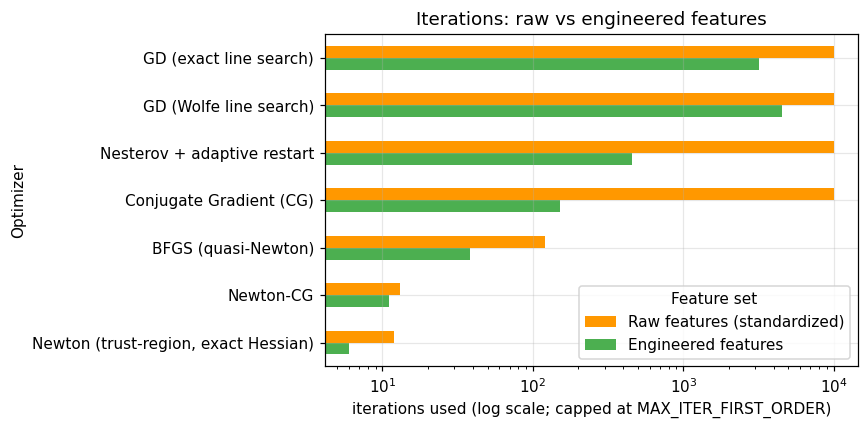

In [ ]:
# =============================================================================
# 9.1 SAME OPTIMIZERS, TWO DIFFERENT FEATURE SETS
# =============================================================================
subset = [N_GD_EXACT, N_GD_WOLFE, N_NESTEROV, N_CG, N_BFGS, N_NCG, N_TRUST]
rows_b = []
for label, A in [("Raw features (standardized)", A_raw_std), ("Engineered features", A_lin_tr)]:
    o = LeastSquares(A, y_train.values)
    ws, fs = o.solve_closed_form()
    _, _, kappa_b = hessian_spectrum(o.A)
    out = run_all_optimizers(o, np.zeros(o.d), only=subset, include_nm=False)
    t, _ = summarize(out, o, ws)
    for name in subset:
        rows_b.append({"Feature set": label, "kappa": kappa_b, "Optimizer": name,
                       "Iterations": t.loc[name, "Iterations"], "Iters to tol": t.loc[name, "Iters to tol"],
                       "Converged": t.loc[name, "Converged"], "Time (s)": round(t.loc[name, "Time (s)"], 4),
                       "Final f-f*": f"{t.loc[name, 'Final f-f*']:.2e}"})
cmp_b = pd.DataFrame(rows_b)
display(cmp_b)

# Compact view: iterations needed by plain gradient descent (Wolfe) in both cases
pivot = cmp_b.pivot(index="Optimizer", columns="Feature set", values="Iterations")
pivot = pivot[["Raw features (standardized)", "Engineered features"]]      # raw = orange, engineered = green
ax = pivot.loc[subset].plot.barh(figsize=(8, 4), logx=True, color=["#FF9800", "#4CAF50"])
ax.set_xlabel("iterations used (log scale; capped at MAX_ITER_FIRST_ORDER)")
ax.set_title("Iterations: raw vs engineered features"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

**How to interpret Experiment B.** If the condition number of the engineered design is smaller than that of the raw one, gradient-type methods need fewer iterations on it, while the quasi-Newton and Newton methods are much less affected — exactly what the theory in Section 2 predicts. Feature engineering therefore acts as **preconditioning**: it improves the problem *before* the optimizer starts.

# 10. EXPERIMENT C — POLYNOMIAL REGRESSION

A polynomial model is still *linear in the weights*; only the design matrix gets extra columns ($x_i^2$, $x_ix_j$, ...). The number of columns grows quickly (degree 4 on 5 features already gives 126 weights) and the columns become strongly correlated, so the Hessian becomes much more ill-conditioned — an excellent stress test for the optimizers.

**Model selection** uses patient-wise 5-fold cross-validation on the training patients only. Feature engineering, feature selection and scaling are **re-fitted inside every fold** (no leakage). The weights of each candidate are found with Newton's method (`trust-exact`), the most reliable optimizer for this small quadratic problem. Candidates:

* linear on all engineered features,
* linear on the top-$K$ features,
* polynomial of degree 2 on all engineered features,
* polynomial of degree $d\in$ `POLY_DEGREES` on the top-$K$ features.

In [ ]:
# =============================================================================
# 10.1 PATIENT-WISE CROSS-VALIDATION OF LINEAR / POLYNOMIAL CANDIDATES
# =============================================================================
def fit_newton(obj):
    """Weights of a least-squares problem by Newton's method (scipy 'trust-exact')."""
    res = minimize(obj.f, np.zeros(obj.d), jac=obj.grad, hess=obj.hess, method="trust-exact",
                   options=dict(gtol=1e-10, maxiter=500))
    return res.x


def make_fold_design(X_tr_raw, y_tr, X_va_raw, degree, top_k):
    """Fit the whole feature pipeline on the fold's training part only, then build design matrices."""
    fe_fold = FeatureEngineer().fit(X_tr_raw, y_tr)
    return build_design(fe_fold.transform(X_tr_raw), y_tr, fe_fold.transform(X_va_raw), degree, top_k)


CANDIDATES = ([("Linear (all features)", 1, None),
               (f"Linear (top-{POLY_TOP_K})", 1, POLY_TOP_K),
               ("Poly d=2 (all features)", 2, None)]
              + [(f"Poly d={d} (top-{POLY_TOP_K})", d, POLY_TOP_K) for d in POLY_DEGREES])

gkf = GroupKFold(n_splits=N_FOLDS)
cv_rows = []
for name, degree, top_k in CANDIDATES:
    val_rmse, tr_rmse, n_w = [], [], None
    for tr, va in gkf.split(X_train_raw, y_train, groups=groups_train):
        A_tr, A_va, _ = make_fold_design(X_train_raw.iloc[tr], y_train.iloc[tr], X_train_raw.iloc[va], degree, top_k)
        o = LeastSquares(A_tr, y_train.iloc[tr].values)
        w = fit_newton(o)
        val_rmse.append(rmse(y_train.iloc[va], A_va @ w))
        tr_rmse.append(rmse(y_train.iloc[tr], A_tr @ w))
        n_w = A_tr.shape[1]
    cv_rows.append({"Candidate": name, "degree": degree, "top_k": top_k, "n_weights": n_w,
                    "Train RMSE": np.mean(tr_rmse), "CV RMSE": np.mean(val_rmse), "CV RMSE std": np.std(val_rmse)})

# Reference: predict the training mean (no features at all) inside the same folds
base_rmse = [rmse(y_train.iloc[va], np.full(len(va), y_train.iloc[tr].mean()))
             for tr, va in gkf.split(X_train_raw, y_train, groups=groups_train)]

cv_df = pd.DataFrame(cv_rows).set_index("Candidate")
cv_df["Gap (CV - Train)"] = cv_df["CV RMSE"] - cv_df["Train RMSE"]
display(cv_df.round(4))
print(f"Reference: mean-only baseline CV RMSE = {np.mean(base_rmse):.4f}")

,degree,top_k,n_weights,Train RMSE,CV RMSE,CV RMSE std,Gap (CV - Train)
Candidate,,,,,,,
Linear (all features),1,NaN,11,10.3430,11.3982,2.4431,1.0552
Linear (top-5),1,5.0,6,10.5757,11.3346,2.3306,0.7589
Poly d=2 (all features),2,NaN,66,8.9754,12.2488,2.2862,3.2734
Poly d=2 (top-5),2,5.0,21,10.0980,11.7883,2.4418,1.6903
Poly d=3 (top-5),3,5.0,56,9.7826,12.0258,2.1963,2.2433
Poly d=4 (top-5),4,5.0,126,9.5030,12.4648,2.4960,2.9619


Reference: mean-only baseline CV RMSE = 10.9602


Selected model: Linear (top-5)   (degree = 1, top_k = 5)


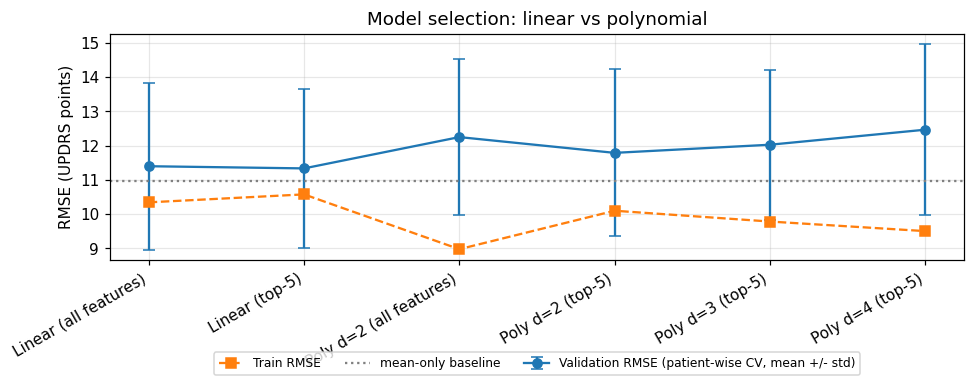

In [ ]:
# =============================================================================
# 10.2 CHOOSE THE MODEL (lowest cross-validation RMSE) AND PLOT TRAIN vs VALIDATION ERROR
# =============================================================================
best_name = cv_df["CV RMSE"].idxmin()
best_degree = int(cv_df.loc[best_name, "degree"])
best_top_k = cv_df.loc[best_name, "top_k"]
best_top_k = None if pd.isna(best_top_k) else int(best_top_k)
print(f"Selected model: {best_name}   (degree = {best_degree}, top_k = {best_top_k})")

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(cv_df))
ax.errorbar(x, cv_df["CV RMSE"], yerr=cv_df["CV RMSE std"], fmt="o-", capsize=4, label="Validation RMSE (patient-wise CV, mean +/- std)")
ax.plot(x, cv_df["Train RMSE"], "s--", label="Train RMSE")
ax.axhline(np.mean(base_rmse), color="gray", ls=":", label="mean-only baseline")
ax.set_xticks(x); ax.set_xticklabels(cv_df.index, rotation=30, ha="right")
ax.set_ylabel("RMSE (UPDRS points)"); ax.set_title("Model selection: linear vs polynomial")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.38), ncol=3)
plt.tight_layout(); plt.show()

Selected design: n = 4640, d = 6 weights
lambda_min = 1.251e-01, lambda_max = 4.069e+00, kappa = 3.25e+01


,Family,Iterations,f evals,grad evals,Hess evals,Time (s),Final f-f*,Rel. error ||w-w*||/||w*||,Iters to tol,Converged,Test RMSE
Optimizer,,,,,,,,,,,
GD (fixed step 1/L),First-order,508,0,509,0,0.0093,6.40e-16,3.37e-09,180,True,10.0409
GD (exact line search),First-order,240,0,241,0,0.0068,5.65e-16,3.14e-09,84,True,10.0409
GD (Wolfe line search),First-order,207,407,396,0,0.0238,7.86e-16,3.73e-09,73,True,10.0409
Nesterov + adaptive restart,Momentum,106,0,107,0,0.0020,1.07e-15,3.59e-09,53,True,10.0409
Adam (plateau decay),Momentum,3059,0,3060,0,0.0819,4.89e-17,3.33e-10,2105,True,10.0409
Conjugate Gradient (CG),Conjugate gradient,22,43,43,0,0.0048,1.28e-14,1.13e-08,8,True,10.0409
BFGS (quasi-Newton),Quasi-Newton,24,30,30,0,0.0042,3.07e-16,1.85e-09,15,True,10.0409
L-BFGS-B (limited-memory QN),Quasi-Newton,22,26,26,0,0.0021,6.58e-16,2.26e-09,12,True,10.0409
Newton-CG,Newton,9,8,8,8,0.0023,1.50e-15,4.92e-09,5,True,10.0409


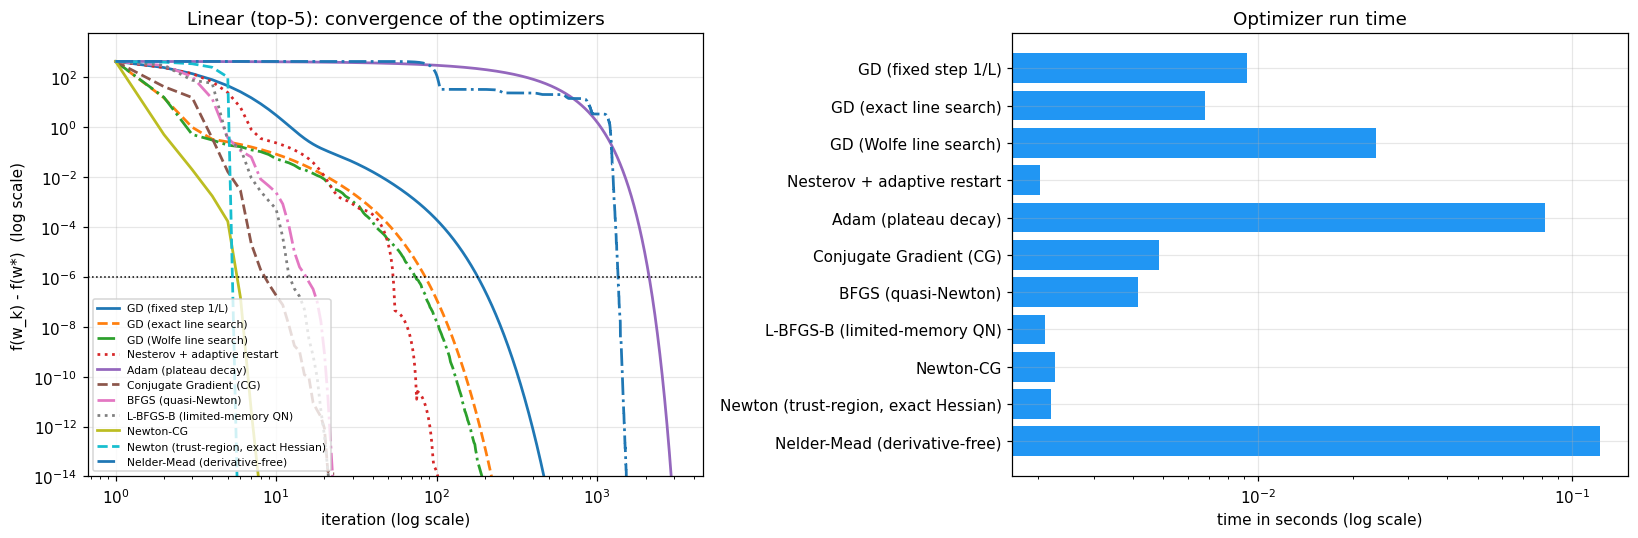

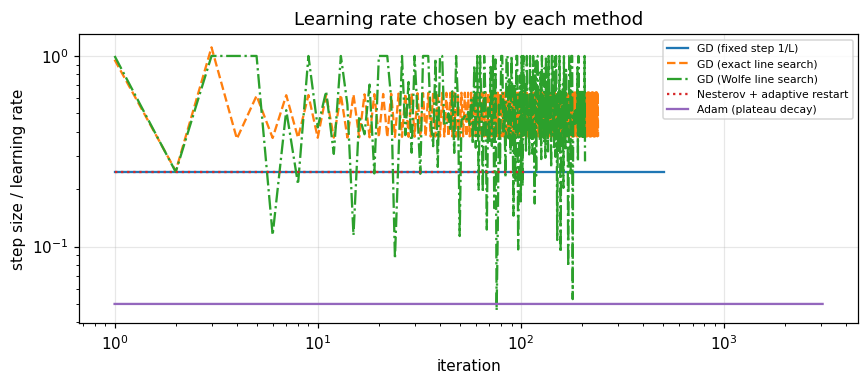

In [ ]:
# =============================================================================
# 10.3 OPTIMIZER COMPARISON ON THE SELECTED MODEL (trained on all training patients)
# =============================================================================
A_fin_tr, A_fin_te, names_fin = build_design(F_train, y_train, F_test, degree=best_degree, top_k=best_top_k)
obj_fin = LeastSquares(A_fin_tr, y_train.values)
w_star_fin, f_star_fin = obj_fin.solve_closed_form()
lo_fin, hi_fin, kappa_fin = hessian_spectrum(obj_fin.A)
print(f"Selected design: n = {obj_fin.n}, d = {obj_fin.d} weights")
print(f"lambda_min = {lo_fin:.3e}, lambda_max = {hi_fin:.3e}, kappa = {fmt_kappa(kappa_fin)}")

res_fin = run_all_optimizers(obj_fin, np.zeros(obj_fin.d), include_nm=(obj_fin.d <= 20))
tbl_fin, gaps_fin = summarize(res_fin, obj_fin, w_star_fin, A_fin_te, y_test.values)
show_table(tbl_fin)
plot_convergence(res_fin, gaps_fin, f"{best_name}: convergence of the optimizers")

Polynomial degree 4 on top-5 features: d = 126 weights, kappa = 7.45e+07


,Family,Iterations,f evals,grad evals,Hess evals,Time (s),Final f-f*,Rel. error ||w-w*||/||w*||,Iters to tol,Converged
Optimizer,,,,,,,,,,
GD (fixed step 1/L),First-order,10000,0,10000,0,0.1579,2.46e+00,9.84e-01,NaN,False
GD (exact line search),First-order,10000,0,10000,0,0.2555,1.96e+00,9.77e-01,NaN,False
GD (Wolfe line search),First-order,10000,20227,20133,0,5.2287,1.70e+00,9.69e-01,NaN,False
Nesterov + adaptive restart,Momentum,10000,0,10000,0,0.2452,1.93e-02,3.97e-01,NaN,False
Adam (plateau decay),Momentum,4103,0,4104,0,0.1274,1.33e+00,9.54e-01,NaN,False
Conjugate Gradient (CG),Conjugate gradient,10001,18559,18559,0,7.1770,5.74e-04,1.00e-01,NaN,False
BFGS (quasi-Newton),Quasi-Newton,1350,1399,1388,0,1.7798,3.56e-10,5.83e-05,1194.0,True
L-BFGS-B (limited-memory QN),Quasi-Newton,10001,11178,11178,0,48.4350,4.40e-05,2.55e-02,NaN,False
Newton-CG,Newton,37,44,44,36,0.1330,1.26e-10,5.04e-05,11.0,True


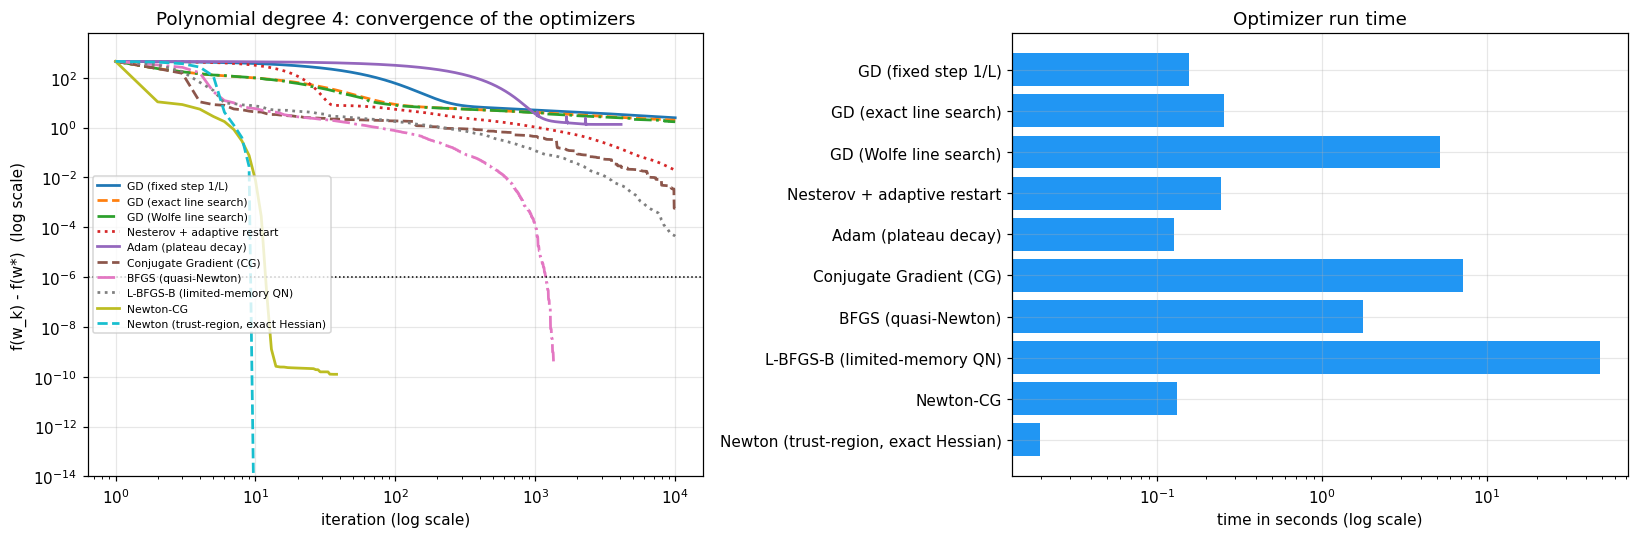

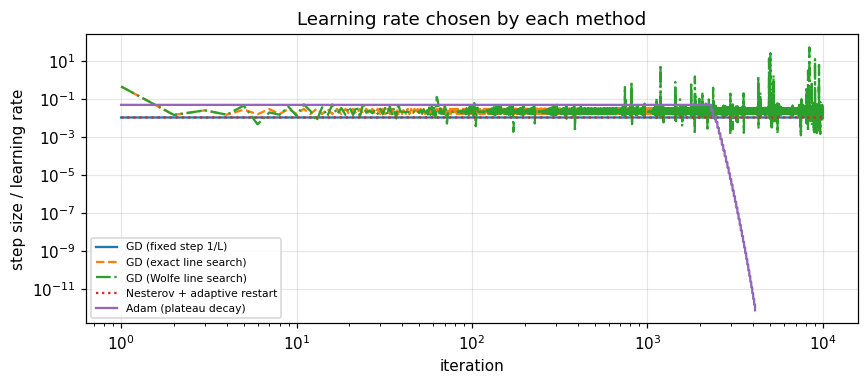

In [ ]:
# =============================================================================
# 10.4 SAME COMPARISON ON A DELIBERATELY HARD POLYNOMIAL (highest degree, ill-conditioned)
# =============================================================================
# The selected model can be simple (e.g. linear).  To see the optimizers under stress we also run
# them on the highest-degree polynomial candidate. This is only an optimization experiment: the
# model is NOT used for the final answer unless it was selected by cross-validation.
hard_degree = max(POLY_DEGREES)
A_hard_tr, A_hard_te, _ = build_design(F_train, y_train, F_test, degree=hard_degree, top_k=POLY_TOP_K)
obj_hard = LeastSquares(A_hard_tr, y_train.values)
w_star_hard, _ = obj_hard.solve_closed_form()
_, _, kappa_hard = hessian_spectrum(obj_hard.A)
print(f"Polynomial degree {hard_degree} on top-{POLY_TOP_K} features: d = {obj_hard.d} weights, "
      f"kappa = {fmt_kappa(kappa_hard)}")

res_hard = run_all_optimizers(obj_hard, np.zeros(obj_hard.d), include_nm=False)
tbl_hard, gaps_hard = summarize(res_hard, obj_hard, w_star_hard)
show_table(tbl_hard)
plot_convergence(res_hard, gaps_hard, f"Polynomial degree {hard_degree}: convergence of the optimizers")

**How to interpret Experiment C.** Polynomial features multiply the number of weights and worsen the conditioning, so first-order methods slow down or hit the iteration cap, whereas Newton / quasi-Newton / CG are far less sensitive. *Optimization accuracy and prediction quality are different things*: even a perfectly converged high-degree polynomial can generalize worse to unseen patients (see the gap between train and validation RMSE in 10.1).

# 11. FINAL EVALUATION ON UNSEEN PATIENTS

The test patients are used **once**, only to report the performance of decisions that were already taken with cross-validation on the training patients. For the selected model, every optimizer that converged is evaluated; they should agree.

In [ ]:
# =============================================================================
# 11.1 TEST-SET METRICS, SANITY CHECKS AND CROSS-CHECK WITH SCIKIT-LEARN
# =============================================================================
# Final weights: Newton (trust-region) solution of the selected model.
w_final = res_fin[N_TRUST]["iterates"][-1]
pred_test = A_fin_te @ w_final


def metrics(y_true, y_pred):
    return {"RMSE": rmse(y_true, y_pred), "MAE": float(mean_absolute_error(y_true, y_pred)),
            "R2": float(r2_score(y_true, y_pred))}


rows_final = {
    "Baseline: predict the training mean": metrics(y_test, np.full(len(y_test), y_train.mean())),
    "Linear (all engineered features)": metrics(y_test, A_lin_te @ w_star_lin),
    f"SELECTED: {best_name}": metrics(y_test, pred_test),
}
final_df = pd.DataFrame(rows_final).T
display(final_df.round(4))
print("(For reference, the previous notebook reported a test R2 of about 0.027 for sklearn LinearRegression on PPE + DFA.)")

# Cross-check 1: scikit-learn's closed-form solver must give the same weights and predictions.
sk = LinearRegression(fit_intercept=False).fit(A_fin_tr, y_train.values)   # intercept already in the ones column
print(f"\nmax |w_newton - w_sklearn| = {np.max(np.abs(w_final - sk.coef_)):.3e}")
print(f"max |prediction difference| on test = {np.max(np.abs(pred_test - sk.predict(A_fin_te))):.3e}")

# Cross-check 2: every optimizer that converged gives (almost) the same test RMSE.
conv = tbl_fin[tbl_fin["Converged"]]
print("Test RMSE of converged optimizers: min = {:.4f}, max = {:.4f}  ({} of {} optimizers converged)".format(
    conv["Test RMSE"].min(), conv["Test RMSE"].max(), len(conv), len(tbl_fin)))

,RMSE,MAE,R2
Baseline: predict the training mean,9.4670,7.9907,-0.0816
Linear (all engineered features),9.6375,8.1696,-0.1209
SELECTED: Linear (top-5),10.0409,8.5727,-0.2167


(For reference, the previous notebook reported a test R2 of about 0.027 for sklearn LinearRegression on PPE + DFA.)

max |w_newton - w_sklearn| = 2.487e-14
max |prediction difference| on test = 4.263e-14
Test RMSE of converged optimizers: min = 10.0409, max = 10.0409  (11 of 11 optimizers converged)


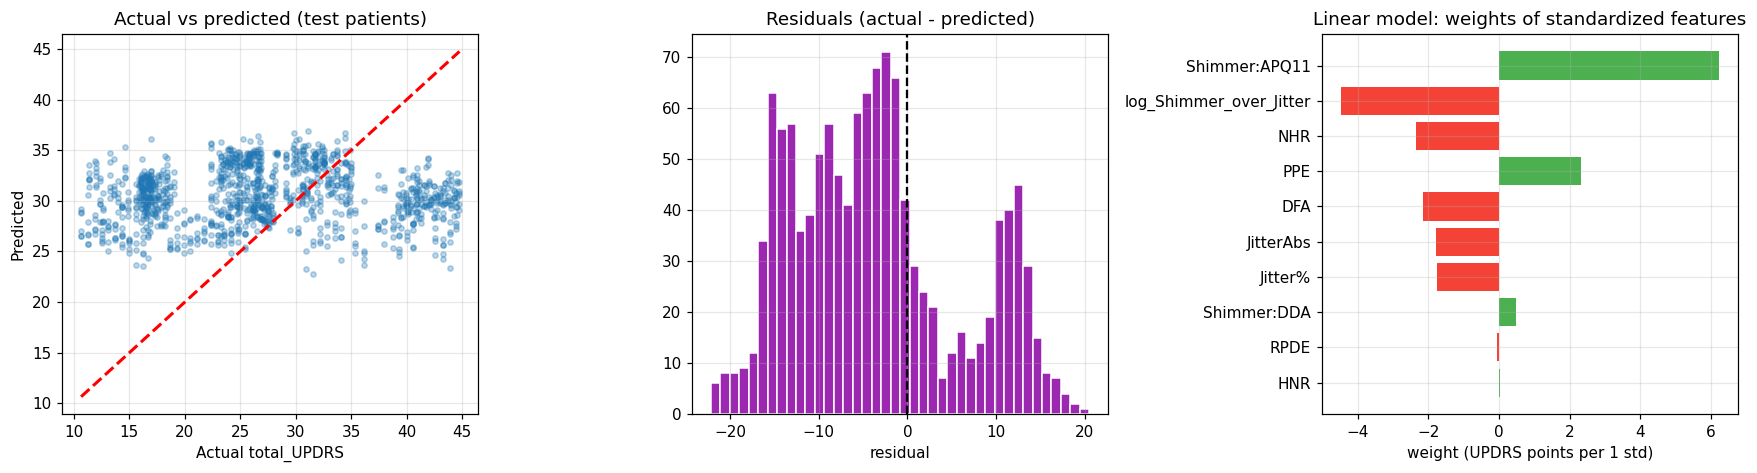

,weight
Shimmer:APQ11,6.2252
log_Shimmer_over_Jitter,-4.4825
NHR,-2.3631
PPE,2.3086
DFA,-2.1540
JitterAbs,-1.7855
Jitter%,-1.7520
Shimmer:DDA,0.4921
RPDE,-0.0713
HNR,0.0286


In [ ]:
# =============================================================================
# 11.2 DIAGNOSTIC PLOTS ON THE TEST PATIENTS
# =============================================================================
resid = y_test.values - pred_test
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

ax[0].scatter(y_test, pred_test, alpha=0.3, s=12)
lim = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ax[0].plot(lim, lim, "r--", lw=2); ax[0].set_xlabel("Actual total_UPDRS"); ax[0].set_ylabel("Predicted")
ax[0].set_title("Actual vs predicted (test patients)")

ax[1].hist(resid, bins=40, color="#9C27B0", edgecolor="white")
ax[1].axvline(0, color="k", ls="--"); ax[1].set_title("Residuals (actual - predicted)"); ax[1].set_xlabel("residual")

# standardized weights of the LINEAR model are directly comparable -> feature importance
coef = pd.Series(w_star_lin[1:], index=names_lin[1:]).sort_values(key=np.abs)
ax[2].barh(coef.index, coef.values, color=np.where(coef.values >= 0, "#4CAF50", "#F44336"))
ax[2].set_title("Linear model: weights of standardized features"); ax[2].set_xlabel("weight (UPDRS points per 1 std)")
plt.tight_layout(); plt.show()

display(coef.sort_values(key=np.abs, ascending=False).to_frame("weight").round(4))

# 12. RESULTS SUMMARY, DISCUSSION AND CONCLUSION


In [ ]:
# =============================================================================
# 12.1 RESULTS SUMMARY
# =============================================================================
def fmt_iters(v):
    return "never (iteration cap reached)" if pd.isna(v) else f"{int(v):,} iterations"


def r2_verdict(r2):
    if r2 < 0.10: return "very weak"
    if r2 < 0.30: return "weak"
    if r2 < 0.50: return "moderate"
    return "good"


lines = []
lines.append(f"**Data.** {len(df):,} recordings from {df['subject#'].nunique()} patients "
             f"(train: {len(X_train_raw):,} recordings / {groups_train.nunique()} patients; "
             f"test: {len(X_test_raw):,} recordings / {groups.iloc[test_idx].nunique()} patients, no patient overlap).")

lines.append(f"**Feature engineering.** {X_train_raw.shape[1]} raw inputs became {F_train.shape[1]} engineered features "
             f"({len(fe.log_cols_)} log-transformed, {len(fe.dropped_)} dropped as redundant: "
             f"{', '.join(fe.dropped_.keys()) if fe.dropped_ else 'none'}). "
             f"The Hessian condition number went from {fmt_kappa(cond_df.loc['Raw features (no scaling)', 'kappa'])} (raw, unscaled) "
             f"and {fmt_kappa(cond_df.loc['Raw features (standardized)', 'kappa'])} (raw, standardized) "
             f"to {fmt_kappa(cond_df.loc['Engineered features', 'kappa'])} (engineered).")

# Experiment A facts
conv_a = tbl_lin[tbl_lin["Converged"]]
slow_a = tbl_lin[~tbl_lin["Converged"]]
fast_name = conv_a["Time (s)"].idxmin() if len(conv_a) else None
fewest_name = conv_a["Iters to tol"].idxmin() if len(conv_a) else None
txt = f"**Experiment A (linear regression, d = {obj_lin.d}).** {len(conv_a)} of {len(tbl_lin)} optimizers reached f - f* < {CONV_TOL:g}. "
if fast_name:
    txt += f"Fastest in wall-clock time: {fast_name} ({conv_a.loc[fast_name, 'Time (s)']:.4f} s). "
    txt += f"Fewest iterations to tolerance: {fewest_name} ({fmt_iters(conv_a.loc[fewest_name, 'Iters to tol'])}). "
if len(slow_a):
    txt += "Did not reach the tolerance within the cap: " + ", ".join(slow_a.index) + ". "
gd_f, gd_w = tbl_lin.loc[N_GD_FIXED, "Iters to tol"], tbl_lin.loc[N_GD_WOLFE, "Iters to tol"]
txt += f"Gradient descent needed {fmt_iters(gd_f)} with the fixed step 1/L versus {fmt_iters(gd_w)} with the Wolfe line search."
lines.append(txt)

# Experiment B facts
sub_b = cmp_b[cmp_b["Optimizer"] == N_GD_WOLFE].set_index("Feature set")
lines.append("**Experiment B (conditioning).** GD with Wolfe line search used "
             f"{int(sub_b.loc['Raw features (standardized)', 'Iterations']):,} iterations on the raw standardized features "
             f"(kappa = {fmt_kappa(sub_b.loc['Raw features (standardized)', 'kappa'])}) and "
             f"{int(sub_b.loc['Engineered features', 'Iterations']):,} iterations on the engineered features "
             f"(kappa = {fmt_kappa(sub_b.loc['Engineered features', 'kappa'])}).")

# Experiment C facts
sel = rows_final[f"SELECTED: {best_name}"]
lin_all_cv = cv_df.loc["Linear (all features)", "CV RMSE"]
lines.append(f"**Experiment C (model selection).** Lowest patient-wise CV RMSE: {best_name} "
             f"({cv_df.loc[best_name, 'CV RMSE']:.3f}; linear on all features: {lin_all_cv:.3f}; "
             f"mean-only baseline: {np.mean(base_rmse):.3f}). "
             + ("A polynomial model was selected." if best_degree > 1 else "No polynomial candidate beat the linear model on unseen patients."))
conv_h = tbl_hard[tbl_hard["Converged"]]
lines.append(f"On the stress test (degree {hard_degree}, d = {obj_hard.d}, kappa = {fmt_kappa(kappa_hard)}) "
             f"{len(conv_h)} of {len(tbl_hard)} optimizers reached the tolerance"
             + (f" (not reached: {', '.join(tbl_hard.index[~tbl_hard['Converged']])})." if len(conv_h) < len(tbl_hard) else "."))

# Final test performance + answer to the main question
base_m = rows_final["Baseline: predict the training mean"]
lines.append(f"**Test performance (unseen patients).** Selected model: RMSE = {sel['RMSE']:.3f}, MAE = {sel['MAE']:.3f}, "
             f"R2 = {sel['R2']:.3f}; the mean-only baseline has RMSE = {base_m['RMSE']:.3f}. "
             f"Prediction quality is {r2_verdict(sel['R2'])}.")

top3 = coef.sort_values(key=np.abs, ascending=False).head(3)
lines.append("**Most influential features (linear model, standardized weights).** "
             + ", ".join(f"{n} ({w:+.2f})" for n, w in top3.items()) + ".")

inputs_txt = "Voice features plus age, sex and test time" if INCLUDE_CLINICAL else "Voice features alone"
verdict = (f"{inputs_txt} do NOT predict total_UPDRS well enough with linear/polynomial regression."
           if sel["R2"] < 0.30 else
           f"{inputs_txt} give a useful, although imperfect, prediction of total_UPDRS with this model.")
lines.append(f"**Answer to RQ4.** {verdict} (Test R2 = {sel['R2']:.3f}; this summary treats R2 < 0.30 as 'not well'. "
             f"With only {groups.iloc[test_idx].nunique()} test patients the estimate is uncertain.)")

display(Markdown("\n\n".join("- " + l for l in lines)))

- **Data.** 5,875 recordings from 42 patients (train: 4,640 recordings / 33 patients; test: 1,235 recordings / 9 patients, no patient overlap).

- **Feature engineering.** 16 raw inputs became 10 engineered features (13 log-transformed, 7 dropped as redundant: Jitter:PPQ5, Jitter:DDP, Jitter:RAP, ShimmerdB, Shimmer, Shimmer:APQ5, Shimmer:APQ3). The Hessian condition number went from 7.61e+13 (raw, unscaled) and 5.90e+08 (raw, standardized) to 8.24e+02 (engineered).

- **Experiment A (linear regression, d = 11).** 11 of 11 optimizers reached f - f* < 1e-06. Fastest in wall-clock time: Newton-CG (0.0039 s). Fewest iterations to tolerance: Newton (trust-region, exact Hessian) (5 iterations). Gradient descent needed 4,737 iterations with the fixed step 1/L versus 1,994 iterations with the Wolfe line search.

- **Experiment B (conditioning).** GD with Wolfe line search used 10,000 iterations on the raw standardized features (kappa = 5.90e+08) and 4,558 iterations on the engineered features (kappa = 8.24e+02).

- **Experiment C (model selection).** Lowest patient-wise CV RMSE: Linear (top-5) (11.335; linear on all features: 11.398; mean-only baseline: 10.960). No polynomial candidate beat the linear model on unseen patients.

- On the stress test (degree 4, d = 126, kappa = 7.45e+07) 3 of 10 optimizers reached the tolerance (not reached: GD (fixed step 1/L), GD (exact line search), GD (Wolfe line search), Nesterov + adaptive restart, Adam (plateau decay), Conjugate Gradient (CG), L-BFGS-B (limited-memory QN)).

- **Test performance (unseen patients).** Selected model: RMSE = 10.041, MAE = 8.573, R2 = -0.217; the mean-only baseline has RMSE = 9.467. Prediction quality is very weak.

- **Most influential features (linear model, standardized weights).** Shimmer:APQ11 (+6.23), log_Shimmer_over_Jitter (-4.48), NHR (-2.36).

- **Answer to RQ4.** Voice features alone do NOT predict total_UPDRS well enough with linear/polynomial regression. (Test R2 = -0.217; this summary treats R2 < 0.30 as 'not well'. With only 9 test patients the estimate is uncertain.)

## Discussion

**Optimization (RQ1).** The learning problem is a convex quadratic, so every optimizer must end at the same minimizer; what differs is the cost of getting there.

* *Learning rate.* A fixed step needs knowledge of $L=\lambda_{\max}(H)$ and is limited by the *smallest* curvature direction. Line search removes this tuning: the exact line search uses the curvature along the current gradient, the Wolfe line search only needs function and gradient values, which makes it applicable to non-quadratic losses as well. Momentum (Nesterov with restart) accelerates progress along flat directions, and Adam adapts the step per coordinate, but it needs a learning-rate schedule to settle precisely.
* *Second-order information.* A pure Newton step would solve the quadratic exactly because it uses the exact Hessian, and the safeguarded variants used here need only a handful of iterations; BFGS/L-BFGS recover most of this benefit from gradients alone; CG needs only Hessian-vector products. Their cost per iteration is higher, but they need far fewer iterations on ill-conditioned problems. For very large $d$, where storing or factorizing $H$ is impossible, L-BFGS and CG are the practical choices.
* *Derivative-free.* Nelder–Mead works only because $d$ is small; the number of function evaluations grows quickly with the dimension.

**Features (RQ2).** Duplicated voice measures (e.g. Jitter:DDP = 3·Jitter:RAP) make $H$ nearly singular. Removing them, taming skewed features and standardizing is expected to reduce $\kappa$ and therefore the work gradient methods must do (Section 12.1 reports the measured values). This is feature engineering viewed as *preconditioning*.

**Modelling (RQ3).** Higher polynomial degrees increase flexibility but also the number of weights and the ill-conditioning. Selection is done with patient-wise cross-validation, because recordings of the same patient are highly similar; a random split would leak patient identity and give over-optimistic results.

**Limitations.**

* The 5,875 recordings come from only 42 patients, so the test set contains very few patients (the estimate of generalization has high variance).
* Only voice features are used by default (`INCLUDE_CLINICAL = False`) to stay consistent with the research question; setting it to `True` adds age, sex and test time as inputs and typically changes the achievable accuracy.
* Plain least squares has no regularization (outside the scope of this lesson); with many polynomial terms this limits generalization.
* Wall-clock times depend on the machine; iteration and evaluation counts are the portable comparison.

## Conclusion

1. The prediction of `total_UPDRS` was formulated as an unconstrained convex optimization problem $\min_w \frac1{2n}\lVert Aw-y\rVert^2$ and solved with gradient descent (fixed step, exact and Wolfe line search), momentum methods (Nesterov with restart, Adam), conjugate gradient, quasi-Newton (BFGS, L-BFGS), Newton methods and Nelder–Mead.
2. All converged optimizers reach the closed-form solution to within the tolerance; they differ in the number of iterations, function/gradient/Hessian evaluations and time (see the tables of Experiments A and C).
3. Line search (instead of a hand-tuned learning rate) and second-order methods are the most reliable choices; feature engineering reduces the condition number and makes every optimizer's job easier (Experiment B).
4. The answer to the research question — how well linear and polynomial models can predict `total_UPDRS` from voice features on unseen patients — is given with numbers in Section 12.1.

**Reproducibility.** Set `SEED`, `INCLUDE_CLINICAL`, `POLY_TOP_K`, `POLY_DEGREES` in Section 3.1 and run the notebook from top to bottom. If there is no internet access, download `parkinsons_updrs.data` from the UCI page and save it next to the notebook.

**References**

* Nocedal, J. & Wright, S. *Numerical Optimization*, 2nd ed., Springer (line search, Wolfe conditions, BFGS, Newton-CG).
* Boyd, S. & Vandenberghe, L. *Convex Optimization*, Cambridge University Press (gradient descent, Newton, condition number).
* O'Donoghue, B. & Candès, E. *Adaptive restart for accelerated gradient schemes*, Found. Comput. Math., 2015.
* Kingma, D. & Ba, J. *Adam: A method for stochastic optimization*, ICLR 2015.
* Tsanas, A., Little, M., McSharry, P., Ramig, L. *Accurate telemonitoring of Parkinson's disease progression by non-invasive speech tests*, IEEE Trans. Biomed. Eng., 2010 (dataset).
* SciPy documentation: `scipy.optimize.minimize`, `scipy.optimize.line_search`.